# End-Review Pipeline: P0 Cache → P1 Baselines → P2 RGAT GNN

This notebook runs the complete **Semester 1 End-Review** pipeline end-to-end:
1. **P0 Cache Verification** — 189 DAIC-WOZ subjects (`3.0 s` windows, `1.5 s` hop, Ellie turns stripped, `158-dim` COVAREP + FORMANT).
2. **P1 Speaker-Independent 5-Fold CV Harness** — stratified on `label × gender`, zero speaker leakage verified.
3. **P1 Baselines** — SVM (RBF), Random Forest, and 2-layer BiLSTM.
4. **P2 Multi-Relational RGAT GNN** — temporal (`E_seq`) + cosine k-NN (`E_knn`, $k=5$) edges, 2-layer `RGATConv`, flat readout, TorchScript export smoke-test.
5. **Unified Evaluation** — UAR, macro-F1, depressed F1/recall, ROC-AUC, bootstrap 95% CIs, training curves, confusion matrices, and AVEC 2016 comparison.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

RESULTS_DIR = ROOT / "results" / "end_review"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
print("Project root:", ROOT)

Project root: C:\Users\sahit\Downloads\Code\speech-detection


## 1. P0 — Load Cached Subjects & Verify Dataset Summary

In [2]:
from src.data.preprocess import build_cache
from src.train.cv import load_cached_subjects

# Uses existing cache if all 189 .pt files are present; builds if missing
meta_df = build_cache(overwrite=False)
cache_dict = load_cached_subjects()

print(f"Loaded {len(cache_dict)} subjects from cache.")
print("Label distribution:", meta_df["label"].value_counts().to_dict())
print("Gender distribution:", meta_df["gender"].value_counts().to_dict())
meta_df.head()

Caching DAIC-WOZ:   0%|          | 0/189 [00:00<?, ?it/s]

Caching DAIC-WOZ:  50%|█████     | 95/189 [00:00<00:00, 904.90it/s]

Caching DAIC-WOZ: 100%|██████████| 189/189 [00:00<00:00, 1135.32it/s]

Cached 189 subjects to C:\Users\sahit\Downloads\Code\speech-detection\data\cache\DAIC_WOZ (avg nodes: 221.4)
Loaded 189 subjects from cache.
Label distribution: {0: 133, 1: 56}
Gender distribution: {1: 102, 0: 87}


,subject_id,label,phq_score,gender,official_split,n_nodes
0,300,0,2,1,test,102
1,301,0,3,1,test,256
2,302,0,4,1,dev,138
3,303,0,0,0,train,256
4,304,0,6,0,train,240


## 2. P1 — Speaker-Independent 5-Fold CV Harness

In [3]:
from src.train.cv import build_or_load_folds, assert_no_speaker_leakage, bootstrap_uar_ci

folds_df = build_or_load_folds()
assert_no_speaker_leakage(folds_df)
print("Zero speaker leakage verified across 5 folds.")
print(folds_df.groupby(["fold", "label"]).size().unstack(fill_value=0))

Zero speaker leakage verified across 5 folds.
label   0   1
fold         
0      27  11
1      27  11
2      27  11
3      26  12
4      26  11


## 3. P1 — Classical Baselines (SVM-RBF & Random Forest)

In [4]:
from src.baselines.svm_rf import run_svm_rf_cv, run_feature_ablation_cv

ablation_df = run_feature_ablation_cv(cache_dict, folds_df, results_dir=RESULTS_DIR)
display(ablation_df.round(4))

svm_rf_folds, svm_rf_oof = run_svm_rf_cv(cache_dict, folds_df, feature_set="set_a_c", results_dir=RESULTS_DIR)
svm_rf_folds.groupby("model")[["uar", "macro_f1", "f1_dep", "roc_auc"]].agg(["mean", "std"]).round(4)

C:\Users\sahit\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\sahit\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\sahit\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\sahit\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\svm\

C:\Users\sahit\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\sahit\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\sahit\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\sahit\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\svm\

C:\Users\sahit\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\sahit\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\sahit\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\sahit\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\svm\

C:\Users\sahit\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\sahit\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\sahit\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\sahit\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\svm\

C:\Users\sahit\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\sahit\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\sahit\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\sahit\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\svm\

,feature_set,model,uar_mean,uar_std,macro_f1_mean,macro_f1_std,f1_dep_mean,f1_dep_std,roc_auc_mean,roc_auc_std
0,covarep,Gaussian NB,0.5496,0.0689,0.5282,0.0704,0.4186,0.0682,0.5910,0.0676
1,covarep,Logistic Regression,0.5367,0.0743,0.5280,0.0716,0.3447,0.1339,0.5585,0.1056
2,covarep,Random Forest,0.5035,0.0901,0.4950,0.0985,0.2540,0.1555,0.5799,0.1099
3,covarep,SVM (RBF),0.5000,0.0000,0.4130,0.0040,0.0000,0.0000,0.4510,0.1323
4,egemaps,Gaussian NB,0.5638,0.0935,0.5373,0.0832,0.4201,0.1174,0.5688,0.0658
5,egemaps,Logistic Regression,0.5472,0.1154,0.5395,0.1168,0.3891,0.1338,0.5556,0.1219
6,egemaps,Random Forest,0.5154,0.1050,0.5072,0.1128,0.2798,0.1818,0.5829,0.0884
7,egemaps,SVM (RBF),0.5000,0.0000,0.4130,0.0040,0.0000,0.0000,0.4887,0.1562
8,set_a,Gaussian NB,0.5582,0.0870,0.5369,0.0820,0.4159,0.1061,0.5691,0.0802
9,set_a,Logistic Regression,0.5343,0.0822,0.5248,0.0831,0.3667,0.1064,0.5199,0.1266


C:\Users\sahit\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\sahit\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\sahit\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\sahit\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\svm\

uar         macro_f1          f1_dep         roc_auc  \
                       mean     std     mean     std    mean     std    mean   
model                                                                          
Gaussian NB          0.5619  0.0885   0.5416  0.0824  0.4191  0.1085  0.5760   
Logistic Regression  0.5698  0.0953   0.5614  0.0959  0.4023  0.1263  0.6006   
Random Forest        0.5317  0.1241   0.5133  0.1459  0.2561  0.2486  0.5791   
SVM (RBF)            0.5000  0.0000   0.4130  0.0040  0.0000  0.0000  0.4813   

                             
                        std  
model                        
Gaussian NB          0.0954  
Logistic Regression  0.1204  
Random Forest        0.1211  
SVM (RBF)            0.1535

## 4. P1 — Sequential Baseline (2-Layer BiLSTM)

In [5]:
from src.baselines.bilstm import run_bilstm_cv

bilstm_folds, bilstm_oof, bilstm_hist = run_bilstm_cv(
    cache_dict, folds_df, feature_set="set_a_c", epochs=30, batch_size=16, lr=1e-3, results_dir=RESULTS_DIR
)
bilstm_folds[["fold", "uar", "macro_f1", "f1_dep", "roc_auc"]].round(4)

,fold,uar,macro_f1,f1_dep,roc_auc
0,0,0.6700,0.6492,0.5385,0.6768
1,1,0.7071,0.6955,0.5833,0.7138
2,2,0.6313,0.5498,0.5143,0.5859
3,3,0.6090,0.6140,0.4211,0.5994
4,4,0.5927,0.5899,0.4348,0.5979


## 5. P2 — Multi-Relational Graph Construction (`E_seq` + `E_knn`) & RGAT GNN

In [6]:
from src.data.build_graph import build_subject_graph
from src.models.classifier import run_gnn_cv, run_export_smoke_test

sample_g = build_subject_graph(cache_dict[300], k=5, feature_set="set_a_c", use_recurrence=True)
print(f"Sample graph (subject 300): {sample_g.num_nodes} nodes, {sample_g.num_edges} edges, "
      f"E_seq={(sample_g.edge_type==0).sum().item()}, E_knn={(sample_g.edge_type==1).sum().item()}, "
      f"E_rec={(sample_g.edge_type==2).sum().item()}")

smoke_ok = run_export_smoke_test(in_dim=sample_g.x.shape[1])
print("TorchScript export smoke-test passed:", smoke_ok)

gnn_folds, gnn_oof, gnn_hist = run_gnn_cv(
    cache_dict, folds_df, feature_set="set_a_c", use_recurrence=True, epochs=50, batch_size=16, lr=7e-4, k=5, results_dir=RESULTS_DIR
)
gnn_folds[["fold", "uar", "macro_f1", "f1_dep", "roc_auc"]].round(4)

Sample graph (subject 300): 102 nodes, 1442 edges, E_seq=202, E_knn=744, E_rec=496


C:\Users\sahit\Downloads\Code\speech-detection\src\models\encoder_rgat.py:19: UserWarning: index_reduce() is in beta and the API may change at any time. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\TensorAdvancedIndexing.cpp:1514.)
  max_per_node.index_reduce_(0, dst, scores, reduce="amax", include_self=True)


TorchScript export smoke-test passed: True


,fold,uar,macro_f1,f1_dep,roc_auc
0,0,0.5993,0.6042,0.3750,0.6734
1,1,0.6801,0.6801,0.5455,0.6835
2,2,0.5152,0.5128,0.3333,0.4141
3,3,0.6090,0.6140,0.4211,0.5032
4,4,0.5420,0.5180,0.4138,0.5105


## 6. Unified Comparison, Bootstrap 95% CIs & Plots

In [7]:
all_folds = pd.concat([svm_rf_folds, bilstm_folds, gnn_folds], ignore_index=True)
all_oof = pd.concat([svm_rf_oof, bilstm_oof, gnn_oof], ignore_index=True)

summary_rows = []
for model_name, grp in all_folds.groupby("model", sort=False):
    oof_sub = all_oof[all_oof["model"] == model_name]
    uar_oof, ci_lo, ci_hi = bootstrap_uar_ci(oof_sub["y_true"].values, oof_sub["y_prob"].values)
    summary_rows.append({
        "model": model_name,
        "uar_mean": grp["uar"].mean(),
        "uar_std": grp["uar"].std(),
        "uar_oof": uar_oof,
        "uar_ci95_low": ci_lo,
        "uar_ci95_high": ci_hi,
        "macro_f1_mean": grp["macro_f1"].mean(),
        "f1_dep_mean": grp["f1_dep"].mean(),
        "roc_auc_mean": grp["roc_auc"].mean(),
    })

summary_df = pd.DataFrame(summary_rows)
summary_df.to_csv(RESULTS_DIR / "summary_comparison.csv", index=False)
summary_df.round(4)

,model,uar_mean,uar_std,uar_oof,uar_ci95_low,uar_ci95_high,macro_f1_mean,f1_dep_mean,roc_auc_mean
0,SVM (RBF),0.5000,0.0000,0.5000,0.5000,0.5000,0.4130,0.0000,0.4813
1,Logistic Regression,0.5698,0.0953,0.5677,0.4926,0.6431,0.5614,0.4023,0.6006
2,Gaussian NB,0.5619,0.0885,0.5597,0.4843,0.6396,0.5416,0.4191,0.5760
3,Random Forest,0.5317,0.1241,0.5296,0.4673,0.5948,0.5133,0.2561,0.5791
4,BiLSTM,0.6420,0.0465,0.6391,0.5647,0.7123,0.6197,0.4984,0.6347
5,RGAT GNN,0.5891,0.0642,0.5888,0.5136,0.6620,0.5858,0.4177,0.5569


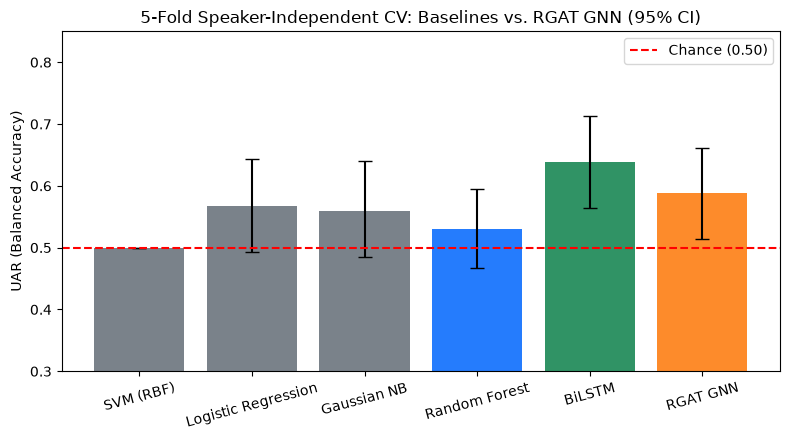

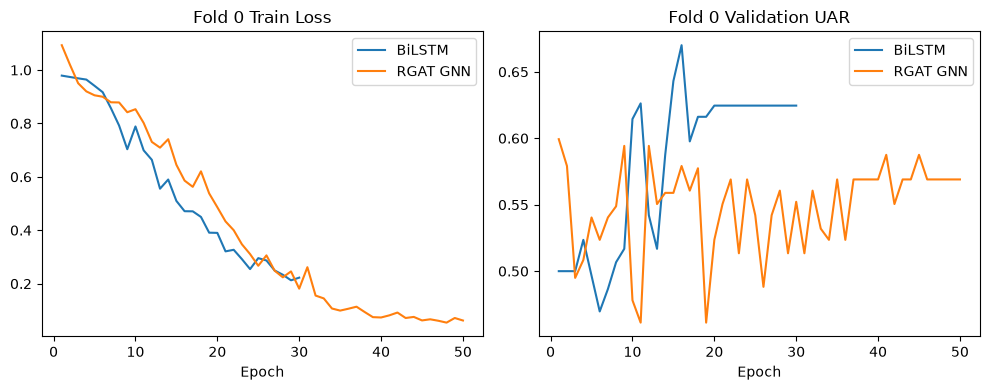

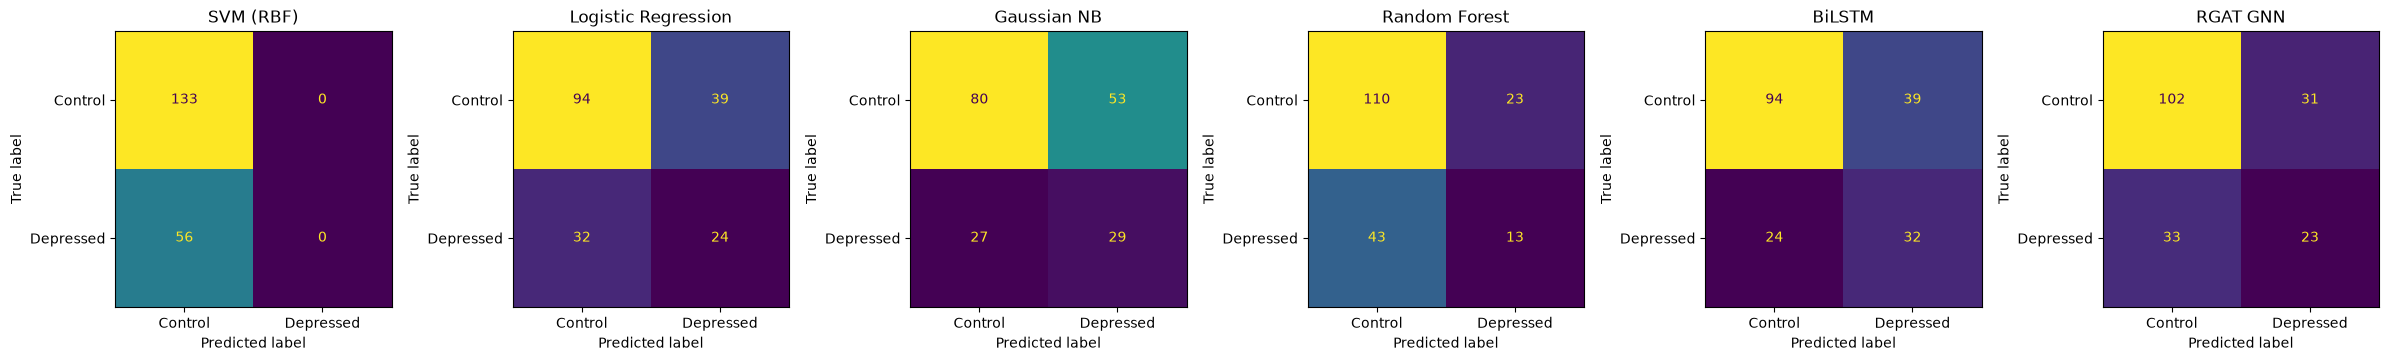

In [8]:
# Plot 1: Model UAR Comparison with 95% Bootstrap CIs
fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(len(summary_df))
y = summary_df["uar_oof"].values
yerr = np.vstack([y - summary_df["uar_ci95_low"].values, summary_df["uar_ci95_high"].values - y])
colors = ["#6c757d", "#6c757d", "#6c757d", "#0d6efd", "#198754", "#fd7e14"]
ax.bar(x, y, yerr=yerr, capsize=5, color=colors[:len(x)], alpha=0.9)
ax.axhline(0.5, ls="--", color="red", label="Chance (0.50)")
ax.set_xticks(x)
ax.set_xticklabels(summary_df["model"], rotation=15)
ax.set_ylabel("UAR (Balanced Accuracy)")
ax.set_ylim(0.3, 0.85)
ax.set_title("5-Fold Speaker-Independent CV: Baselines vs. RGAT GNN (95% CI)")
ax.legend()
plt.tight_layout()
plt.savefig(RESULTS_DIR / "uar_comparison.png", dpi=150)
plt.show()

# Plot 2: Training Curves (BiLSTM vs. RGAT GNN, Fold 0)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for name, hist in [("BiLSTM", bilstm_hist[0]), ("RGAT GNN", gnn_hist[0])]:
    hdf = pd.DataFrame(hist)
    axes[0].plot(hdf["epoch"], hdf["train_loss"], label=name)
    axes[1].plot(hdf["epoch"], hdf["val_uar"], label=name)
axes[0].set_title("Fold 0 Train Loss"); axes[0].set_xlabel("Epoch"); axes[0].legend()
axes[1].set_title("Fold 0 Validation UAR"); axes[1].set_xlabel("Epoch"); axes[1].legend()
plt.tight_layout()
plt.savefig(RESULTS_DIR / "training_curves_fold0.png", dpi=150)
plt.show()

# Plot 3: Confusion Matrices (Out-of-Fold)
fig, axes = plt.subplots(1, len(summary_df), figsize=(4 * len(summary_df), 3.6))
for ax, model_name in zip(axes, summary_df["model"]):
    sub = all_oof[all_oof["model"] == model_name]
    cm = confusion_matrix(sub["y_true"], (sub["y_prob"] >= 0.5).astype(int))
    ConfusionMatrixDisplay(cm, display_labels=["Control", "Depressed"]).plot(ax=ax, colorbar=False)
    ax.set_title(model_name)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "confusion_matrices.png", dpi=150)
plt.show()